# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Mã dùng chung nằm trong `day10/` (nhãn, model, huấn luyện, suy luận, reward, ảnh minh hoạ); notebook này gọi các hàm đó theo đúng thứ tự GUIDE.

**Cách chạy:** Runtime → Change runtime type → **T4 GPU**, rồi chạy lần lượt từ trên xuống.
Adapter, dự đoán và `run.json` được lưu thẳng vào Google Drive (`MyDrive/day10_work`). Nếu Colab bị ngắt: chạy lại toàn bộ mục 0 và ô đầu của mục 1, rồi chạy lại ô đang dở. Thí nghiệm đã train xong sẽ không train lại.

## 0. Môi trường (Colab T4)

In [1]:
REPO_URL = "https://github.com/vuthien3002-sys/K4-Track-4-Day10-VisionLanguageModel.git"
REPO_DIR = "/content/K4-Track-4-Day10-VisionLanguageModel"
!nvidia-smi -L
import os
if not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!pip -q install -r requirements-colab.txt
!pip -q uninstall -y torchao  # torchao 0.10 có sẵn trên Colab làm peft 0.21 báo ImportError; bài này không dùng torchao

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-3f2c2533-2aa1-14fd-2172-b7021f7cf2d9)
/content/K4-Track-4-Day10-VisionLanguageModel
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 128.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 62.0 MB/s eta 0:00:00


In [2]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
# Chưa tạo secret thì ô này hỏi nhập tay (ẩn ký tự, không lưu vào notebook).
import os
from getpass import getpass
from google.colab import userdata


def secret(name, required=True):
    try:
        return userdata.get(name)
    except Exception:  # chưa tạo secret hoặc chưa bật "Notebook access"
        return getpass(f"{name} (lấy trong kaggle.json): ") if required else None


os.environ['KAGGLE_USERNAME'] = secret('KAGGLE_USERNAME').strip()
os.environ['KAGGLE_KEY'] = secret('KAGGLE_KEY').strip()
if os.environ['KAGGLE_KEY'].startswith('KGAT_'):  # token Kaggle kiểu mới
    os.environ['KAGGLE_API_TOKEN'] = os.environ['KAGGLE_KEY']
hf = secret('HF_TOKEN', required=False)  # tuỳ chọn: tải model nhanh hơn
if hf:
    os.environ['HF_TOKEN'] = hf
print("đã nạp KAGGLE_USERNAME và KAGGLE_KEY (không in giá trị)")

đã nạp KAGGLE_USERNAME và KAGGLE_KEY (không in giá trị)


In [3]:
from google.colab import drive
drive.mount("/content/drive")

import json, shutil, subprocess, sys
from pathlib import Path
sys.path.insert(0, os.getcwd())
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
from day10 import vlm
from day10.report import draw, grid, load_preds, output_stats, summary_rows

WORK = Path("/content/drive/MyDrive/day10_work")  # adapter, dự đoán, run.json: còn nguyên khi Colab ngắt
WORK.mkdir(parents=True, exist_ok=True)
Path("report/figures").mkdir(parents=True, exist_ok=True)


def backup():
    """Chép report/ (evidence, ảnh) sang Drive."""
    shutil.copytree("report", WORK / "report", dirs_exist_ok=True)


def restore():
    if (WORK / "report").exists():
        shutil.copytree(WORK / "report", "report", dirs_exist_ok=True)


def score(name, pred, out, run=None, split="test", coord="norm1000"):
    """Gọi trọng tài scripts/score.py; meta lấy thẳng từ run.json để không gõ tay sai."""
    cmd = [sys.executable, "scripts/score.py", "--pred", str(pred), "--name", name, "--out", str(out),
           "--split", split, "--coord", coord]
    if run:
        for k in ("trainable_params", "peak_vram_gb", "train_minutes"):
            cmd += ["--meta", f"{k}={run[k]}"]
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout, r.stderr)
    backup()


def load_run(name):
    return json.loads((WORK / name.lower() / "run.json").read_text(encoding="utf-8"))


restore()
print("evidence đã có:", sorted(p.name for p in Path("report/evidence").glob("*.json")))

Mounted at /content/drive
evidence đã có: ['e0.json', 'e1.json']


In [4]:
!python -m pytest -q
!python -m pytest day10/tests -q

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.37s
.......................                                                  [100%]
23 passed in 0.08s


## 1. Dữ liệu: tải và chia split theo phiên quay

In [5]:
if not Path("data/splits/meta.json").exists():
    !python scripts/prepare_data.py --kaggle

from scripts.labcommon import CLASSES, read_jsonl
splits = {s: read_jsonl(f"data/splits/{s}.jsonl") for s in ("train", "val", "test")}

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:11<00:00, 17.5MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [6]:
from day10.labels import session_overlap, split_stats

meta = json.loads(Path("data/splits/meta.json").read_text(encoding="utf-8"))
print("dataset_version:", meta["dataset_version"])
for s, rows in splits.items():
    n, boxes = split_stats(rows)
    print(f"{s:5s} {n:5d} ảnh  {boxes}  sessions={len({r['session'] for r in rows})}")
overlap = session_overlap(splits)
print("session trùng giữa các split:", {k: sorted(v) for k, v in overlap.items()})
assert all(not v for v in overlap.values())

dataset_version: d10-21e4070301
train  1422 ảnh  {'pothole': 1074, 'crack': 1750, 'manhole': 691}  sessions=13
val     276 ảnh  {'pothole': 66, 'crack': 470, 'manhole': 103}  sessions=2
test    311 ảnh  {'pothole': 121, 'crack': 299, 'manhole': 163}  sessions=3
session trùng giữa các split: {('test', 'train'): [], ('test', 'val'): [], ('train', 'val'): []}


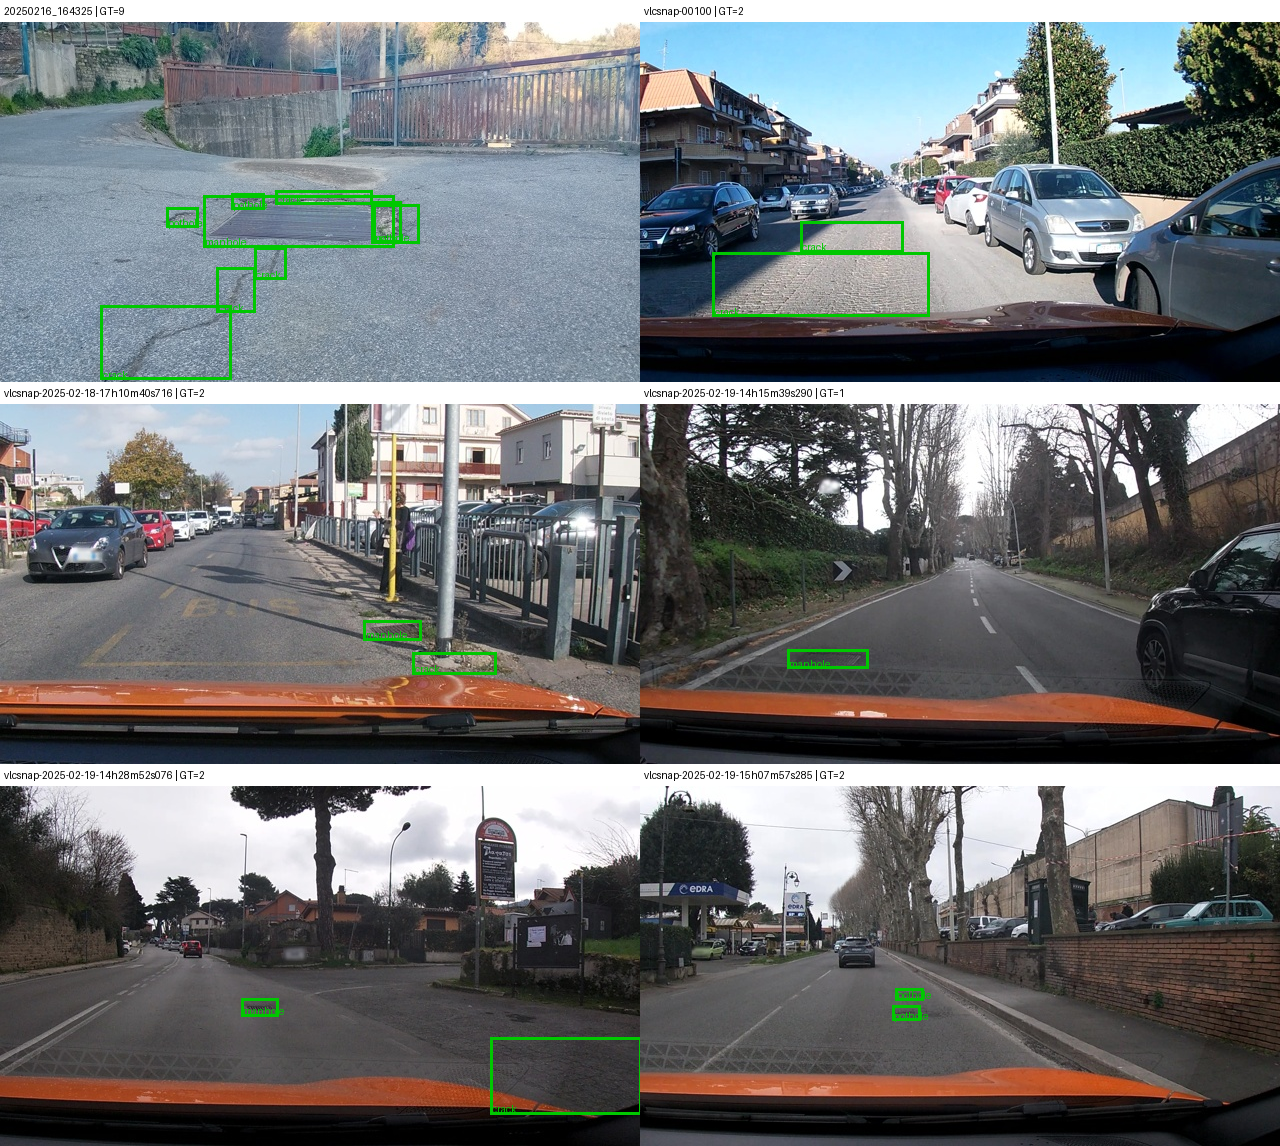

In [7]:
samples = [r for r in splits["train"] if r["objects"]][::200][:6]
sheet = grid([draw(r) for r in samples])
sheet.save("report/figures/data_samples.jpg")
backup()
sheet

## 2. Nhãn: YOLO → JSON thang 0–1000

Locate road damage in this image. Detect only objects of classes: pothole, crack, manhole. Output a JSON list of objects with label and bbox_2d coordinates normalized on a 0-1000 scale: [{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. If no damage is found, output []. 

đáp án: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
sai số lớn nhất khi quy ngược về pixel: 5.00 px


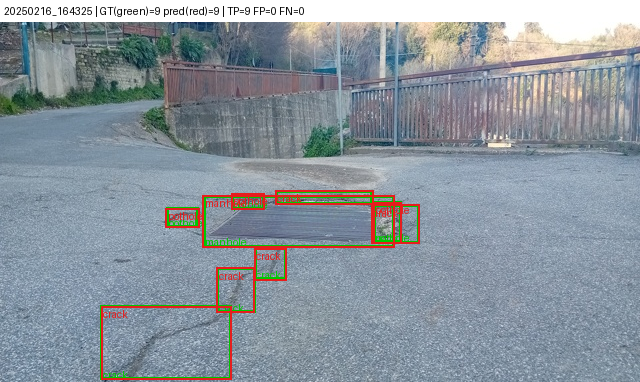

In [8]:
from day10.labels import PROMPT_NORM1000, box_to_pixels, objects_to_answer, yolo_to_box, yolo_to_pixels

e = samples[0]
answer = objects_to_answer(e["objects"])
print(PROMPT_NORM1000, "\n")
print("đáp án:", answer)

# Quy ngược thang 0–1000 → pixel và so với box gốc trên toàn bộ train
err = max(abs(a - b) for r in splits["train"] for o in r["objects"]
          for a, b in zip(box_to_pixels(yolo_to_box(o["label"], o["yolo"])["bbox_2d"], r["width"], r["height"]),
                          yolo_to_pixels(o["yolo"], r["width"], r["height"])))
print(f"sai số lớn nhất khi quy ngược về pixel: {err:.2f} px")
draw(e, raw=answer)  # box đỏ (từ JSON) phải trùng box xanh (gốc)

## 3. E0: zero-shot

In [9]:
model, processor = vlm.load_model()
print("Linear 4-bit theo khối:", vlm.check_quantization(model))  # chỉ được có 'llm'
params, _ = vlm.param_breakdown(model)
for k, v in params.items():
    print(f"{k:22s} {v / 1e6:8.1f}M")
print(f"{'tổng':22s} {sum(params.values()) / 1e6:8.1f}M")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Linear 4-bit theo khối: {'llm': 252}
vit                       306.2M
projector.merger           27.3M
projector.deepstack        81.8M
llm                      4022.5M
tổng                     4437.8M


In [10]:
vlm.predict(model, processor, splits["test"], WORK / "e0.jsonl")
score("E0", WORK / "e0.jsonl", "report/evidence/e0.json")

E0 [test] n=311 valid=0.842 P=0.122 R=0.069 F1=0.088 CI95=0.062-0.115 meanIoU=0.600 FP/img=0.92
   pothole  P=0.286 R=0.066 F1=0.107
   crack    P=0.044 R=0.030 F1=0.036
   manhole  P=0.240 R=0.141 F1=0.178
 


In [11]:
preds0 = load_preds(WORK / "e0.jsonl")
for e in splits["test"][:5]:
    print(e["image_id"], "\n  GT :", objects_to_answer(e["objects"]), "\n  RAW:", repr(preds0[e["image_id"]][:300]))
print(output_stats(splits["test"], preds0))

vlcsnap-00200 
  GT : [{"label":"crack","bbox_2d":[352,642,534,728]},{"label":"manhole","bbox_2d":[894,756,1000,847]}] 
  RAW: '[{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]'
vlcsnap-00201 
  GT : [{"label":"manhole","bbox_2d":[856,725,919,789]},{"label":"crack","bbox_2d":[558,736,731,825]}] 
  RAW: '[]'
vlcsnap-00202 
  GT : [{"label":"manhole","bbox_2d":[275,672,405,722]}] 
  RAW: '[{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]'
vlcsnap-00203 
  GT : [{"label":"crack","bbox_2d":[322,631,759,775]}] 
  RAW: '[]'
vlcsnap-00204 
  GT : [{"label":"manhole","bbox_2d":[248,622,353,678]}] 
  RAW: '[{"label": "manhole", "bbox_2d": [257, 627, 325, 657]}]'
{'n': 311, 'invalid_rate': 0.15755627009646303, 'empty_rate': 0.05144694533762058, 'gt_empty_rate': 0.0, 'boxes_per_image': 1.0514469453376205, 'gt_boxes_per_image': 1.8745980707395498, 'mean_box_area_frac': 0.06162368501529052}


In [12]:
del model
vlm.free()

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [13]:
from PIL import Image
from transformers import AutoProcessor
from day10.labels import objects_to_answer, prompt_for

processor = AutoProcessor.from_pretrained(vlm.MODEL_ID)
ex = [r for r in splits["train"] if r["objects"]][0]
img = Image.open(Path("data") / ex["image_path"]).convert("RGB")
item = vlm.encode_example(processor, img, prompt_for(), objects_to_answer(ex["objects"]))
tb = vlm.token_breakdown(processor, item)
print({k: v for k, v in tb.items() if k != "answer_decoded"})
print("phần được tính loss:", repr(tb["answer_decoded"]))
print(f"tỷ lệ token được tính loss: {tb['answer'] / tb['total']:.1%}")
assert tb["image"] == 220

batch = vlm.collate([item, item], processor.tokenizer.pad_token_id)
print({k: tuple(v.shape) for k, v in batch.items()})

{'total': 562, 'image': 220, 'answer': 250, 'prompt_text_and_template': 92, 'image_grid_thw': [1, 22, 40], 'image_from_grid': 220}
phần được tính loss: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
tỷ lệ token được tính loss: 44.5%
{'input_ids': (2, 562), 'attention_mask': (2, 562), 'labels': (2, 562), 'mm_token_type_ids': (2, 562), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [14]:
print("LoRA LLM:", vlm.LLM_TARGETS)
print("LoRA ViT:", vlm.VIT_TARGETS)
for n in ("e1", "e2", "e3"):
    print(n, vlm.load_config(n))

# E3 chứa cả ba phần: LoRA LLM (E1), + projector (E2), + LoRA ViT (E3)
model, processor = vlm.load_model()
model, matched = vlm.apply_setup(model, vlm.load_config("e3"))
n_llm = sum("language_model" in m for m in matched)
print(f"module LoRA: LLM={n_llm} (kỳ vọng 252), ViT={len(matched) - n_llm} (kỳ vọng 96)")
by = {}
for n, p in model.named_parameters():
    if p.requires_grad:
        key = "projector" if any(k in n for k in vlm.PROJECTOR_KEYS) else ("lora_vit" if "visual" in n else "lora_llm")
        by[key] = by.get(key, 0) + p.numel()
print({k: f"{v:,}" for k, v in by.items()})
del model
vlm.free()

LoRA LLM: model\.language_model\.layers\.\d+\.(?:self_attn\.[qkvo]_proj|mlp\.(?:gate|up|down)_proj)
LoRA ViT: model\.visual\.blocks\.\d+\.(?:attn\.(?:qkv|proj)|mlp\.linear_fc[12])
e1 {'name': 'E1', 'description': 'LoRA chỉ trên LLM; đóng băng ViT và projector.', 'model_id': 'Qwen/Qwen3-VL-4B-Instruct', 'quantization': 'nf4-4bit', 'lora': {'r': 16, 'alpha': 32, 'dropout': 0.05, 'targets': 'llm'}, 'train_projector': False, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}
e2 {'name': 'E2', 'description': 'E1 + mở đầy đủ projector (visual.merger và visual.deepstack_merger_list).', 'model_id': 'Qwen/Qwen3-VL-4B-Instruct', 'quantization': 'nf4-4bit', 'lora': {'r': 16, 'alpha': 32, 'dropout': 0.05, 'targets': 'llm'}, 'train_projector': True, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 300, 'seed': 42}
e3 {'name': 'E3', 'description': 'E2 + LoRA trên các khối attention và MLP của ViT.', 'model_id': 'Qwen/Qwen3-VL-4B-Instruct', 'quantization': 'nf4-

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

module LoRA: LLM=252 (kỳ vọng 252), ViT=96 (kỳ vọng 96)
{'lora_vit': '6,291,456', 'projector': '109,105,152', 'lora_llm': '33,030,144'}


## 6. Vòng huấn luyện
Chạy thử 10 bước trước (khoảng 5 phút) để bắt lỗi, rồi mới chạy E1, E2, E3 (mỗi cái 300 bước + suy luận 311 ảnh test).

In [15]:
smoke = dict(vlm.load_config("e1"), max_steps=10)
model, processor = vlm.load_model()
model, _ = vlm.apply_setup(model, smoke)
vlm.train(model, processor, splits["train"][:80], smoke, WORK / "smoke")
(WORK / "smoke_val.jsonl").unlink(missing_ok=True)
vlm.predict(model, processor, splits["val"][:8], WORK / "smoke_val.jsonl")
for r in read_jsonl(WORK / "smoke_val.jsonl"):
    print(repr(r["raw"][:200]))
del model
vlm.free()

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


bước 1/10  loss=1.9778  lr=2.00e-04  0.1 phút  VRAM đỉnh=5.66 GB
bước 10/10  loss=0.7278  lr=0.00e+00  0.7 phút  VRAM đỉnh=6.35 GB
4/8 ảnh  0.6 phút
8/8 ảnh  1.2 phút
'[{"label":"crack","bbox_2d":[100,400,150,450]},{"label":"crack","bbox_2d":[300,450,400,500]}]'
'[{"label":"crack","bbox_2d":[12,450,150,550]},{"label":"crack","bbox_2d":[150,450,250,550]},{"label":"crack","bbox_2d":[250,450,350,550]},{"label":"crack","bbox_2d":[350,450,450,550]},{"label":"crack"'
'[{"label":"crack","bbox_2d":[0,500,100,600]},{"label":"crack","bbox_2d":[100,500,200,600]},{"label":"crack","bbox_2d":[200,500,300,600]},{"label":"crack","bbox_2d":[300,500,400,600]},{"label":"crack",'
'[{"label":"crack","bbox_2d":[12,450,100,500]},{"label":"crack","bbox_2d":[12,450,100,500]},{"label":"crack","bbox_2d":[12,450,100,500]},{"label":"crack","bbox_2d":[12,450,100,500]},{"label":"crack","b'
'[{"label":"crack","bbox_2d":[122,420,288,520]},{"label":"crack","bbox_2d":[322,420,488,520]}]'
'[{"label":"crack","bbox_2d":[32

In [16]:
run1, pred1 = vlm.run_or_resume("E1", vlm.load_config("e1"), splits["train"], splits["test"], WORK)
score("E1", pred1, "report/evidence/e1.json", run1)

E1: đã có đủ dự đoán, dùng lại /content/drive/MyDrive/day10_work/e1.jsonl
E1 [test] n=311 valid=0.994 P=0.262 R=0.245 F1=0.254 CI95=0.219-0.291 meanIoU=0.685 FP/img=1.29
   pothole  P=0.224 R=0.157 F1=0.184
   crack    P=0.157 R=0.197 F1=0.175
   manhole  P=0.774 R=0.399 F1=0.526
 


In [17]:
run2, pred2 = vlm.run_or_resume("E2", vlm.load_config("e2"), splits["train"], splits["test"], WORK)
score("E2", pred2, "report/evidence/e2.json", run2)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E2: 252 module LoRA, 142,135,296 tham số huấn luyện
bước 1/300  loss=2.0734  lr=1.33e-05  0.1 phút  VRAM đỉnh=6.12 GB
bước 10/300  loss=0.7649  lr=1.33e-04  0.6 phút  VRAM đỉnh=7.29 GB
bước 20/300  loss=0.7227  lr=2.00e-04  1.2 phút  VRAM đỉnh=8.04 GB
bước 30/300  loss=0.6589  lr=1.99e-04  1.8 phút  VRAM đỉnh=8.04 GB
bước 40/300  loss=0.5998  lr=1.96e-04  2.4 phút  VRAM đỉnh=8.04 GB
bước 50/300  loss=0.6057  lr=1.93e-04  3.0 phút  VRAM đỉnh=8.04 GB
bước 60/300  loss=0.5936  lr=1.88e-04  3.5 phút  VRAM đỉnh=8.04 GB
bước 70/300  loss=0.6239  lr=1.82e-04  4.1 phút  VRAM đỉnh=8.04 GB
bước 80/300  loss=0.5714  lr=1.75e-04  4.7 phút  VRAM đỉnh=8.04 GB
bước 90/300  loss=0.6260  lr=1.68e-04  5.3 phút  VRAM đỉnh=8.04 GB
bước 100/300  loss=0.5819  lr=1.59e-04  5.9 phút  VRAM đỉnh=8.04 GB
bước 110/300  loss=0.6123  lr=1.50e-04  6.5 phút  VRAM đỉnh=8.04 GB
bước 120/300  loss=0.6315  lr=1.40e-04  7.1 phút  VRAM đỉnh=8.04 GB
bước 130/300  loss=0.6202  lr=1.30e-04  7.7 phút  VRAM đỉnh=8.04 GB
bước 14

In [18]:
run3, pred3 = vlm.run_or_resume("E3", vlm.load_config("e3"), splits["train"], splits["test"], WORK)
score("E3", pred3, "report/evidence/e3.json", run3)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: 348 module LoRA, 148,426,752 tham số huấn luyện


/content/K4-Track-4-Day10-VisionLanguageModel/day10/vlm.py:268: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


bước 1/300  loss=2.0734  lr=1.33e-05  0.1 phút  VRAM đỉnh=6.25 GB
bước 10/300  loss=0.7375  lr=1.33e-04  0.8 phút  VRAM đỉnh=7.47 GB
bước 20/300  loss=0.7028  lr=2.00e-04  1.5 phút  VRAM đỉnh=8.22 GB
bước 30/300  loss=0.6438  lr=1.99e-04  2.2 phút  VRAM đỉnh=8.22 GB
bước 40/300  loss=0.5582  lr=1.96e-04  3.0 phút  VRAM đỉnh=8.22 GB
bước 50/300  loss=0.5472  lr=1.93e-04  3.7 phút  VRAM đỉnh=8.22 GB
bước 60/300  loss=0.5817  lr=1.88e-04  4.5 phút  VRAM đỉnh=8.22 GB
bước 70/300  loss=0.6259  lr=1.82e-04  5.2 phút  VRAM đỉnh=8.22 GB
bước 80/300  loss=0.5539  lr=1.75e-04  6.0 phút  VRAM đỉnh=8.22 GB
bước 90/300  loss=0.5851  lr=1.68e-04  6.7 phút  VRAM đỉnh=8.22 GB
bước 100/300  loss=0.5280  lr=1.59e-04  7.4 phút  VRAM đỉnh=8.22 GB
bước 110/300  loss=0.5470  lr=1.50e-04  8.2 phút  VRAM đỉnh=8.22 GB
bước 120/300  loss=0.6042  lr=1.40e-04  9.0 phút  VRAM đỉnh=8.22 GB
bước 130/300  loss=0.5875  lr=1.30e-04  9.7 phút  VRAM đỉnh=8.22 GB
bước 140/300  loss=0.5025  lr=1.19e-04  10.5 phút  VRAM đỉn

## 7. Suy luận và chấm E1–E3: bảng tổng hợp, ảnh minh hoạ, phân tích

In [19]:
print("| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |")
print("|---|---|---|---|---|---|---|---|---|---|---|")
print("\n".join(summary_rows()))

ev = {n: json.loads(Path(f"report/evidence/{n.lower()}.json").read_text(encoding="utf-8")) for n in ("E1", "E2", "E3")}
BEST = max(ev, key=lambda n: ev[n]["micro"]["f1"])
print("\nsetup có F1 cao nhất:", BEST)

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|
| E0 | E0 | 0 |  |  | 0.088 | [0.062, 0.115] | 0.92 | 0.107 | 0.036 | 0.178 |
| E1 | E1 | 33030144 | 9.62 | 17.4 | 0.254 | [0.219, 0.291] | 1.29 | 0.184 | 0.175 | 0.526 |
| E2 | E2 | 142135296 | 8.04 | 17.8 | 0.335 | [0.298, 0.376] | 1.07 | 0.178 | 0.273 | 0.598 |
| E3 | E3 | 148426752 | 8.22 | 22.4 | 0.405 | [0.360, 0.449] | 0.97 | 0.284 | 0.319 | 0.676 |

setup có F1 cao nhất: E3


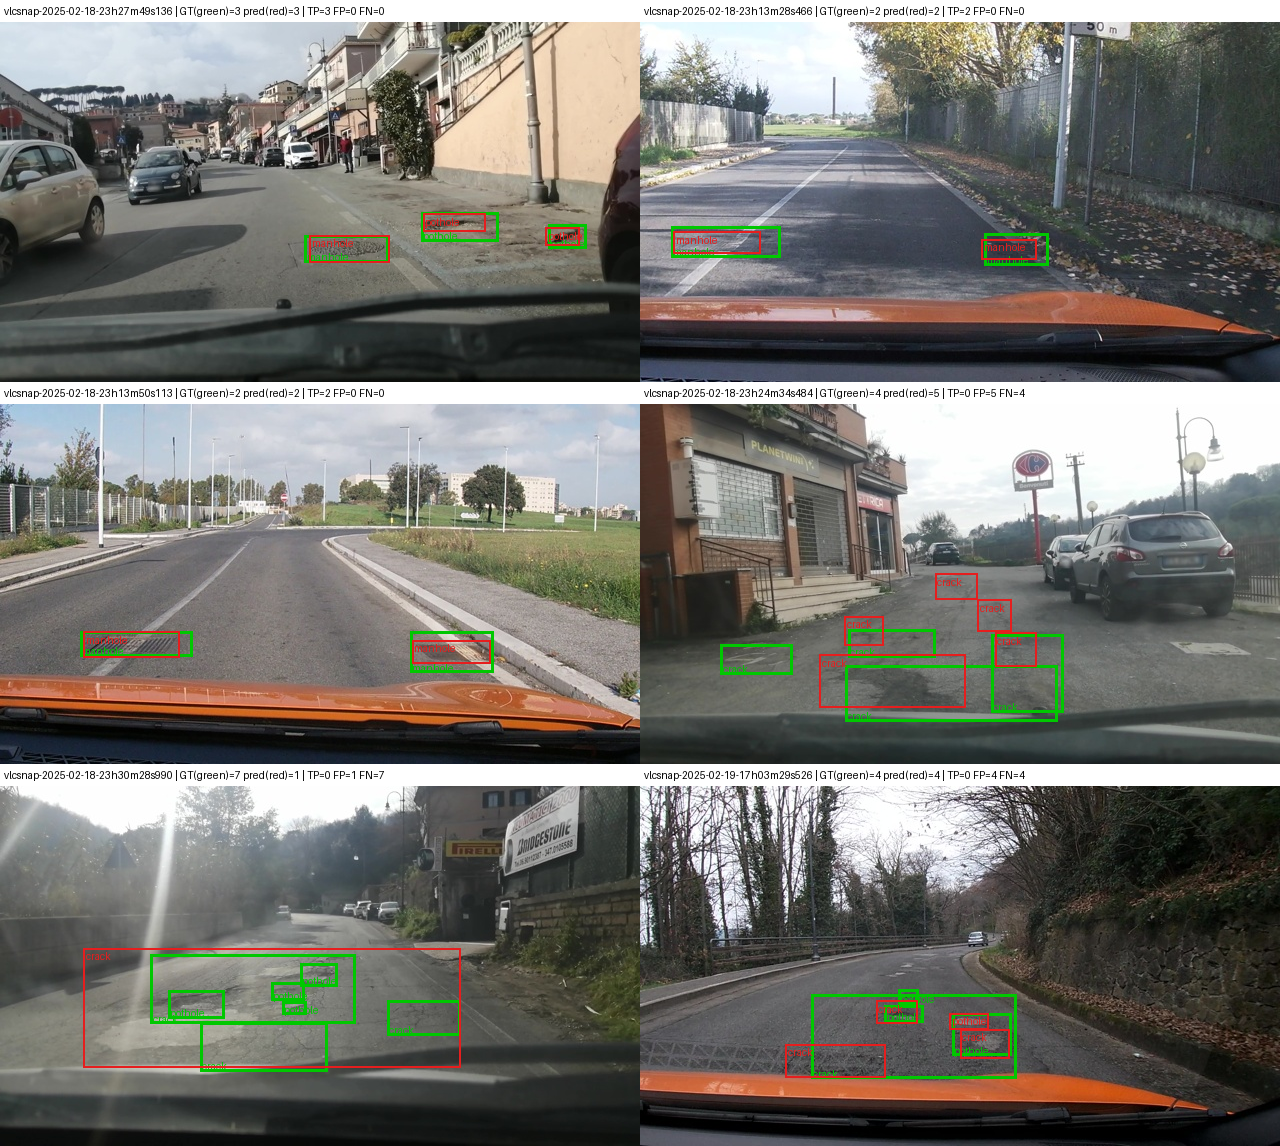

In [20]:
from day10.report import pick_examples

preds = load_preds(WORK / f"{BEST.lower()}.jsonl")
good, bad = pick_examples(splits["test"], preds)
imgs = []
for tag, group in (("good", good), ("bad", bad)):
    for i, e in enumerate(group, 1):
        im = draw(e, preds[e["image_id"]])
        im.save(f"report/figures/{BEST.lower()}_{tag}_{i}.jpg")
        imgs.append(im)
sheet = grid(imgs)
sheet.save(f"report/figures/{BEST.lower()}_examples.jpg")
backup()
sheet  # hàng trên: dự đoán đúng; hàng dưới: sai nhiều nhất. Xanh = đúng, đỏ = dự đoán

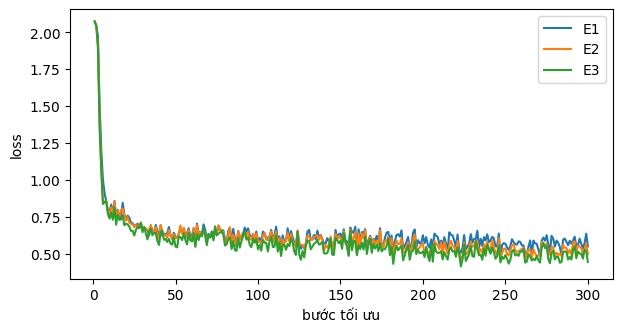

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for n in ("E1", "E2", "E3"):
    h = load_run(n)["history"]
    ax.plot([x["step"] for x in h], [x["loss"] for x in h], label=n)
ax.set_xlabel("bước tối ưu"); ax.set_ylabel("loss"); ax.legend()
fig.savefig("report/figures/loss_curves.png", dpi=120, bbox_inches="tight")
backup()

In [22]:
# Câu 3: chấm cùng dự đoán (thang 0–1000) như thể là pixel → F1 ra sao?
(WORK / "checks").mkdir(exist_ok=True)
score(f"{BEST} chấm như pixel", WORK / f"{BEST.lower()}.jsonl", WORK / "checks" / "best_as_pixel.json", coord="pixel")

# Câu 9: kích thước box và số mẫu từng lớp
import statistics
for c in CLASSES:
    areas = [o["yolo"][2] * o["yolo"][3] for r in splits["train"] for o in r["objects"] if o["label"] == c]
    print(f"{c:8s} train boxes={len(areas):5d}  diện tích trung vị={statistics.median(areas):.2%} khung hình  "
          f"F1 test {BEST}={ev[BEST]['per_class'][c]['f1']:.3f}")

E3 chấm như pixel [test] n=311 valid=1.000 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.70
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000
 
pothole  train boxes= 1074  diện tích trung vị=0.38% khung hình  F1 test E3=0.284
crack    train boxes= 1750  diện tích trung vị=1.35% khung hình  F1 test E3=0.319
manhole  train boxes=  691  diện tích trung vị=0.39% khung hình  F1 test E3=0.676


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
E4 chọn biến `data_size`: 10% ảnh train so với 100%, giữ nguyên mọi thứ khác của setup tốt nhất (kể cả 300 bước). Giá trị 100% chính là setup tốt nhất đã chạy ở mục 6.

In [23]:
from day10.labels import subset

ev = {n: json.loads(Path(f"report/evidence/{n.lower()}.json").read_text(encoding="utf-8")) for n in ("E1", "E2", "E3")}
BEST = max(ev, key=lambda n: ev[n]["micro"]["f1"])
cfg4 = vlm.load_config(BEST.lower())
train10 = subset(splits["train"], 0.1, seed=42)
print(f"E4 dựa trên {BEST}: {len(train10)} ảnh train (10%, seed=42)")

run4, pred4 = vlm.run_or_resume("E4_data_0.1", cfg4, train10, splits["test"], WORK)
score(f"E4 {BEST} data_size=0.1", pred4, "report/evidence/e4_data_0.1.json", run4)
score(f"E4 {BEST} data_size=1.0", WORK / f"{BEST.lower()}.jsonl", "report/evidence/e4_data_1.0.json", load_run(BEST))
print("\n".join(summary_rows()))

E4 dựa trên E3: 142 ảnh train (10%, seed=42)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E4_data_0.1: 348 module LoRA, 148,426,752 tham số huấn luyện
bước 1/300  loss=1.9497  lr=1.33e-05  0.1 phút  VRAM đỉnh=6.15 GB
bước 10/300  loss=0.8293  lr=1.33e-04  0.7 phút  VRAM đỉnh=7.47 GB
bước 20/300  loss=0.7058  lr=2.00e-04  1.5 phút  VRAM đỉnh=7.67 GB
bước 30/300  loss=0.6535  lr=1.99e-04  2.2 phút  VRAM đỉnh=7.67 GB
bước 40/300  loss=0.5387  lr=1.96e-04  3.0 phút  VRAM đỉnh=7.67 GB
bước 50/300  loss=0.5044  lr=1.93e-04  3.7 phút  VRAM đỉnh=7.67 GB
bước 60/300  loss=0.5425  lr=1.88e-04  4.5 phút  VRAM đỉnh=7.67 GB
bước 70/300  loss=0.4881  lr=1.82e-04  5.2 phút  VRAM đỉnh=7.67 GB
bước 80/300  loss=0.4565  lr=1.75e-04  6.0 phút  VRAM đỉnh=7.67 GB
bước 90/300  loss=0.4298  lr=1.68e-04  6.7 phút  VRAM đỉnh=7.67 GB
bước 100/300  loss=0.3801  lr=1.59e-04  7.5 phút  VRAM đỉnh=7.67 GB
bước 110/300  loss=0.3625  lr=1.50e-04  8.3 phút  VRAM đỉnh=7.67 GB
bước 120/300  loss=0.3201  lr=1.40e-04  9.0 phút  VRAM đỉnh=7.67 GB
bước 130/300  loss=0.3087  lr=1.30e-04  9.7 phút  VRAM đỉnh=7.67 G

**E5 (tuỳ chọn, +10).** Chạy test reward trước, rồi GRPO 60 bước từ adapter tốt nhất, suy luận test và chấm.

In [24]:
!python -m pytest day10/tests/test_reward.py -q

............                                                             [100%]
12 passed in 0.02s


In [25]:
from day10 import grpo

model, processor, logs = grpo.run_grpo(WORK / BEST.lower(), splits["train"], WORK / "e5", vlm.load_config("e5"))
vlm.predict(model, processor, splits["test"], WORK / "e5.jsonl")
del model
vlm.free()
score("E5", WORK / "e5.jsonl", "report/evidence/e5.json")
shutil.copy2(WORK / "e5" / "grpo_log.json", "report/e5_grpo_log.json")
backup()

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.


đã nạp lại 24 tensor projector từ /content/drive/MyDrive/day10_work/e3/extra_trainable.pt


Step,Training Loss
1,0.253795
2,0.011105
3,0.184170
4,0.202313
5,0.123691
6,0.126835
7,0.058826
8,0.207610
9,0.049413
10,-0.112422


GRPO xong, VRAM đỉnh 5.65 GB, log: /content/drive/MyDrive/day10_work/e5/grpo_log.json
4/311 ảnh  0.1 phút
44/311 ảnh  1.5 phút
84/311 ảnh  2.6 phút
124/311 ảnh  4.2 phút
164/311 ảnh  6.1 phút
204/311 ảnh  7.7 phút
244/311 ảnh  9.4 phút
284/311 ảnh  11.0 phút
311/311 ảnh  12.1 phút
E5 [test] n=311 valid=1.000 P=0.481 R=0.395 F1=0.434 CI95=0.388-0.481 meanIoU=0.690 FP/img=0.80
   pothole  P=0.388 R=0.273 F1=0.320
   crack    P=0.356 R=0.321 F1=0.337
   manhole  P=0.821 R=0.620 F1=0.706
 


E3 {'n': 311, 'invalid_rate': 0.0, 'empty_rate': 0.0, 'gt_empty_rate': 0.0, 'boxes_per_image': 1.698, 'gt_boxes_per_image': 1.875, 'mean_box_area_frac': 0.022}
E5 {'n': 311, 'invalid_rate': 0.0, 'empty_rate': 0.0, 'gt_empty_rate': 0.0, 'boxes_per_image': 1.537, 'gt_boxes_per_image': 1.875, 'mean_box_area_frac': 0.025}
| E0 | E0 | 0 |  |  | 0.088 | [0.062, 0.115] | 0.92 | 0.107 | 0.036 | 0.178 |
| E1 | E1 | 33030144 | 9.62 | 17.4 | 0.254 | [0.219, 0.291] | 1.29 | 0.184 | 0.175 | 0.526 |
| E2 | E2 | 142135296 | 8.04 | 17.8 | 0.335 | [0.298, 0.376] | 1.07 | 0.178 | 0.273 | 0.598 |
| E3 | E3 | 148426752 | 8.22 | 22.4 | 0.405 | [0.360, 0.449] | 0.97 | 0.284 | 0.319 | 0.676 |
| E4_DATA_0.1 | E4 E3 data_size=0.1 | 148426752 | 7.67 | 22.6 | 0.271 | [0.237, 0.306] | 1.69 | 0.212 | 0.182 | 0.567 |
| E4_DATA_1.0 | E4 E3 data_size=1.0 | 148426752 | 8.22 | 22.4 | 0.405 | [0.360, 0.449] | 0.97 | 0.284 | 0.319 | 0.676 |
| E5 | E5 | 0 |  |  | 0.434 | [0.388, 0.481] | 0.80 | 0.320 | 0.337 | 0.706 |


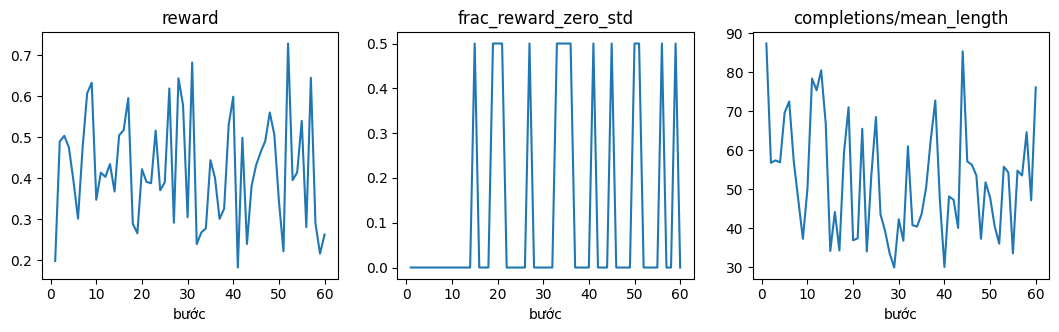

In [26]:
# Nếu Colab ngắt khi đang suy luận E5: nạp lại adapter GRPO và chạy tiếp
# model, processor = vlm.load_trained(WORK / "e5"); vlm.predict(model, processor, splits["test"], WORK / "e5.jsonl")

logs = json.loads((WORK / "e5" / "grpo_log.json").read_text(encoding="utf-8"))
steps = [l for l in logs if "reward" in l]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, key in zip(axes, ("reward", "frac_reward_zero_std", "completions/mean_length")):
    ax.plot([l["step"] for l in steps], [l[key] for l in steps]); ax.set_title(key); ax.set_xlabel("bước")
fig.savefig("report/figures/e5_grpo.png", dpi=120, bbox_inches="tight")

# Dấu hiệu reward hacking: tỷ lệ '[]', số box/ảnh, diện tích box so với SFT
for n in (BEST, "E5"):
    print(n, {k: round(v, 3) for k, v in output_stats(splits["test"], load_preds(WORK / f"{n.lower()}.jsonl")).items()})
print("\n".join(summary_rows()))
backup()

## 9. Mang kết quả về máy để commit
Tải `report.zip`, giải nén đè vào thư mục `report/` của repo trên máy, rồi commit. Đồng thời File → Download → Download .ipynb để lưu notebook đã chạy (có output) đè lên `lab_day10.ipynb`.

In [27]:
backup()
!cd /content/K4-Track-4-Day10-VisionLanguageModel && zip -qr /content/report.zip report
from google.colab import files
files.download("/content/report.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>